In [ ]:
!pip install netket

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 695.1/695.1 kB 7.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 179.2/179.2 kB 9.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 23.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.3/2.3 MB 22.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.6/42.6 kB 2.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 18.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 102.0/102.0 MB 4.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.4/56.4 kB 2.6 MB/s eta 0:00:00
  Attempting uninstall: jaxlib
    Found existing installation: jaxlib 0.4.33
    Uninstalling jaxlib-0.4.33:
      Successfully uninstalled jaxlib-0.4.33
  Attempting uninstall: jax
    Found existing installation: jax 0.4.33
    Uninstalling jax-0.4.33:
      Successfully uninstalled jax-0.4.33


In [ ]:
# Netket and JAX
import netket as nk

import netket.nn as nknn
from netket.operator.spin import sigmax, sigmay, sigmaz
from scipy.sparse.linalg import eigsh
import jax
import jax.numpy as jnp
import jax.random as random
import flax
import flax.linen as nn


import time
import math as m
import numpy as np
import matplotlib.pyplot as plt
import json


In [ ]:
def create_hilbert_space(dim, size, pbc, total_magn):
    """
    Create a hypercube lattice and the corresponding Hilbert space for a system of spin-1/2 particles.

    ParametersCreaperiodic
    Dim : int
        The spatial dimensionality (D) of the hypercube lattice.
    size : int
        The length (L) of the lattice in each dimension.
    pbc : bool
        Apply periodic boundary conditions.
    total_magn : bool
        If True, the Hilbert space is constructed with a fixed total magnetization (total_sz);
        if False, no magnetization constraint is imposed.

    Returns
    g : nk.graph.Hypercube
        A NetKet hypercube graph representing the lattice structure.
    hi : nk.hilbert.Spin
        The Hilbert space for spin-1/2 particles on the lattice.

    Notes
    - The ground state magnetization is set to 0 for an even number of sites and 0.5 for an odd number.
    - A random initial state is generated using a fixed JAX random key to ensure reproducibility.
    """
    D = dim
    L = size
    periodic_boundary_conditions = pbc

    g = nk.graph.Hypercube(length=L, n_dim=D, pbc= periodic_boundary_conditions)

    total_z_magn = (L**D % 2) / 2
    if total_magn == True:
        hi = nk.hilbert.Spin(s=1/2, total_sz=total_z_magn,  N=L**D)
    else:
        #hi = nk.hilbert.Spin(s=1/2,total_sz=0,  N=L**D)
        hi = nk.hilbert.Spin(s=1/2,  N=L**D)

    hi.random_state(jax.random.key(0), 3)

    return g, hi


In [ ]:
def calculate_second_neighbor_links(D, g, L, periodic_boundary_conditions):
    """
    Calculate the second-neighbor links in a lattice graph for a given spatial dimension.

    Parameters
    D : int
        The spatial dimensionality of the lattice (currently supported for D = 1).
    g : nk.graph.Hypercube or similar graph object
        The lattice graph with a method 'nodes()' returning all node indices.
    L : int
        The linear size of the lattice (total number of nodes in one dimension).
    pbc : bool
        Indicates whether periodic boundary conditions are applied to the lattice.

    Returns
    list of tuple
        A list of tuples, where each tuple (node, neighbor) represents a pair of nodes that are
        second neighbors in the lattice.
    """
    second_neighbor_links = []

    for node in g.nodes():
        if D == 1:
            if periodic_boundary_conditions == True:
                if (node + 2) % L != node and abs(node - (node + 2) % L) > 1:
                    second_neighbor_links.append((node, (node + 2) %  L))
            else:
                if node + 2 in g.nodes():
                    second_neighbor_links.append((node, (node + 2) %  L))

    return second_neighbor_links

In [ ]:
def build_heisenberg_hamiltonian(hi, J1, J2, D, L, g, pbc):
    """
    Construct the Heisenberg Hamiltonian with first- and second-neighbor interactions.

    Parameters
    hi : nk.hilbert.Spin
        Hilbert space representing the spin-1/2 particles on the lattice.
    J1 : float
        Coupling constant for the first-neighbor Heisenberg interactions.
    J2 : float
        Coupling constant for the second-neighbor interactions.
    D : int
        Spatial dimensionality of the lattice.
    L : int
        Linear size of the lattice (number of nodes in one dimension).
    g : nk.graph.Hypercube or similar graph object
        Graph object defining the connectivity of the lattice.
    pbc : bool
        Flag indicating whether periodic boundary conditions are applied.

    Returns
    nk.operator.LocalOperator
        The Heisenberg Hamiltonian operator incorporating both first- and second-neighbor interactions.
    """

    H = nk.operator.LocalOperator(hi, dtype = complex)

    for edge in g.edges():
        H+= J1*nk.operator.spin.sigmax(hi, edge[0])*nk.operator.spin.sigmax(hi, edge[1])
        H+= J1*nk.operator.spin.sigmay(hi, edge[0])*nk.operator.spin.sigmay(hi, edge[1])
        H+= J1*nk.operator.spin.sigmaz(hi, edge[0])*nk.operator.spin.sigmaz(hi, edge[1])

    second_neighbor_links = calculate_second_neighbor_links(D, g, L, pbc)

    for edge in second_neighbor_links:
        H+= J2*nk.operator.spin.sigmax(hi, edge[0])*nk.operator.spin.sigmax(hi, edge[1])
        H+= J2*nk.operator.spin.sigmay(hi, edge[0])*nk.operator.spin.sigmay(hi, edge[1])
        H+= J2*nk.operator.spin.sigmaz(hi, edge[0])*nk.operator.spin.sigmaz(hi, edge[1])

    return H


In [ ]:
def exact_diagonalization(H, n_egval = 1):
    """
    Perform exact diagonalization of a Hamiltonian to obtain its eigenvalues and eigenvectors.

    Parameters
    H : nk.operator.LocalOperator
        The Hamiltonian operator to be diagonalized.
    n_egval : int, optional
        The number of eigenvalues (and eigenvectors) to compute. Default is 1 (ground state only).

    Returns
    tuple
        A tuple (E_ground_state, eig_vals, eig_vecs) where:
            E_ground_state (float): The lowest eigenvalue, representing the ground state energy.
            eig_vals (np.ndarray): Array of computed eigenvalues.
            eig_vecs (np.ndarray): Array of corresponding eigenvectors.
    """

    sp_h=H.to_sparse()
    sp_h.shape

    eig_vals, eig_vecs = eigsh(sp_h, k=n_egval, which="SA")

    print("Eigenvalues:", eig_vals)

    E_ground_state = eig_vals[0]

    return E_ground_state, eig_vals, eig_vecs

In [ ]:
def define_observables(hi, g):
    """
    Define spin observables for a spin-1/2 system on a lattice.

    Parameters
    ----------
    hi : nk.hilbert.Spin
        The Hilbert space of the spin-1/2 particles.
    g : nk.graph.Hypercube or similar graph object
        The graph that defines the connectivity of the spin sites (nodes).

    Returns
    -------
    tuple
        A tuple (OX, OY, OZ, OTot) where:
            OX (nk.operator.LocalOperator): Total spin observable along the x-axis.
            OY (nk.operator.LocalOperator): Total spin observable along the y-axis.
            OZ (nk.operator.LocalOperator): Total spin observable along the z-axis.
            OTot (nk.operator.LocalOperator): Total spin observable, summing the x, y, and z components.
    """

    OX = nk.operator.LocalOperator(hi, dtype=complex)
    OY = nk.operator.LocalOperator(hi, dtype=complex)
    OZ = nk.operator.LocalOperator(hi, dtype=complex)
    OTot = nk.operator.LocalOperator(hi, dtype=complex)

    for node in g.nodes():
        OX += nk.operator.spin.sigmax(hi, node)
        OY += nk.operator.spin.sigmay(hi, node)
        OZ += nk.operator.spin.sigmaz(hi, node)
        OTot += nk.operator.spin.sigmax(hi, node) + nk.operator.spin.sigmay(hi, node) + nk.operator.spin.sigmaz(hi, node)

    return OX, OY, OZ, OTot

In [ ]:
class FFNN(nn.Module):
    """A feed-forward network that outputs a single real scalar.
    """
    hidden_dims: tuple = (64, 64)
    param_dtype: any = np.complex128

    @nn.compact
    def __call__(self, x):

        for dim in self.hidden_dims:
            x = nn.Dense(
                features=dim,
                use_bias=True,
                param_dtype=self.param_dtype,
                kernel_init=nn.initializers.normal(stddev=0.01),
                bias_init=nn.initializers.normal(stddev=0.01),
            )(x)
            x = nn.relu(x)

        x = jnp.sum(x, axis=-1)
        return x


In [ ]:
class SymFFNN(nn.Module):
    """
    A feed-forward neural network that enforces translational symmetry in its input.
    """
    hidden_dims: tuple = (64, 64)
    param_dtype: any = np.complex128

    @nn.compact
    def __call__(self, x):

        # Enforce translational symmetry by centering the input:
        # Subtract the mean of the input along the last axis.
        x = x - jnp.mean(x, axis=-1, keepdims=True)

        for dim in self.hidden_dims:
            x = nn.Dense(
                features=dim,
                use_bias=True,
                param_dtype=self.param_dtype,
                kernel_init=nn.initializers.normal(stddev=0.01),
                bias_init=nn.initializers.normal(stddev=0.01),
            )(x)
            x = nn.relu(x)

        x = jnp.sum(x, axis=-1)
        return x


In [ ]:
class NKRBM(nn.Module):
    """
    Neural Kernel Restricted Boltzmann Machine (NKRBM)..
    """
    alpha: float | int = 1

    @nn.compact
    def __call__(self, input):

        num_hidden = int(self.alpha * input.shape[-1])

        x = nn.Dense(
            name="Dense",
            features=num_hidden,
            param_dtype=np.float64,
            use_bias=True,
            kernel_init=nn.initializers.normal(stddev=0.01),
            bias_init=nn.initializers.normal(stddev=0.01),
        )(input)

        x = nknn.log_cosh(x)
        x = jnp.sum(x, axis=-1)

        v_bias = self.param(
            "visible_bias",
            nn.initializers.normal(stddev=0.01),
            (input.shape[-1],),
            np.float64,
        )

        out_bias = jnp.dot(input, v_bias)


        return x + out_bias


In [ ]:
def define_training_parameters(H, hi, g, model, optimizer, sampler, n_samp, l_rate, d_shift):
    """
    Set up the training parameters for a variational Monte Carlo (VMC) simulation.
    """
    if sampler == "Exchange":
        sa = nk.sampler.MetropolisExchange(hilbert=hi, graph=g, d_max=2)
    elif sampler == "Local":
        sa = nk.sampler.MetropolisLocal(hilbert=hi)
    elif sampler == "Hamiltonian":
        sa = nk.sampler.MetropolisHamiltonian(hilbert=hi, hamiltonian=H)
    elif sampler == "Exact":
        sa = nk.sampler.ExactSampler(hilbert=hi)
    else:
        raise ValueError(f"Unknown sampler type: {sampler}")

    vs = nk.vqs.MCState(sa, model, n_samples=n_samp)

    if optimizer == "SDG":
        opt = nk.optimizer.Sgd(learning_rate=l_rate)
    elif optimizer == "Momentum":
        opt = nk.optimizer.Momentum(learning_rate=l_rate, nesterov=True)
    elif optimizer == "AdaGrad":
        opt = nk.optimizer.AdaGrad(learning_rate=l_rate)
    else:
        raise ValueError(f"Unknown optimizer type: {optimizer}")

    sr = nk.optimizer.SR(diag_shift=d_shift)

    gs = nk.VMC(hamiltonian=H, optimizer=opt, variational_state=vs, preconditioner=sr)

    return gs, vs


In [ ]:
def run_model(gs, H, vs, steps, observables, eig_vals):
    """
    Execute the variational Monte Carlo (VMC) training and evaluate the model's performance.
    """
    log=nk.logging.RuntimeLog()
    gs.run(n_iter=steps,out=log, obs=observables)

    model_energy=vs.expect(H)
    error=abs((model_energy.mean-eig_vals)/eig_vals)

    return log, model_energy, error

In [ ]:

def convergence_point(data, Eg):
    """
    Determine the training iteration at which the model's energy converges within 1% of the exact energy.
    """
    E_error = [abs(data["Energy"].Mean[i] - [Eg]) for i in range(len(data["Energy"]))]

    for i in E_error:
        if i == E_error[-1]:
            index = len(E_error) -1

        if np.real(i[0]) <= abs(np.real([Eg][0])/ 100) :
            index = np.argmax(E_error == i)
            print("Convergence step:" , index, "\n",
                "Convergence energy:", np.real(data["Energy"].Mean[index]), "\n",
                "Error:", np.real(i[0]) )
            break

    print("Final energy:", np.real(data["Energy"].Mean[-1] ))
    print("Exact energy:", [Eg][0] )

    return index, np.real(data["Energy"].Mean[index]), np.real(data["Energy"].Mean[-1] )

In [ ]:

def plot(data, Eg, observables, steps):

    plt.errorbar(data["Energy"].iters, data["Energy"].Mean, yerr=data["Energy"].Sigma, label="FFNN with no PBC")

    if observables == True:
        plt.errorbar(data["PauliX"].iters, data["PauliX"].Mean, yerr=data["PauliX"].Sigma, label="X")
        plt.errorbar(data["PauliY"].iters, data["PauliY"].Mean, yerr=data["PauliY"].Sigma, label="Y")
        plt.errorbar(data["PauliZ"].iters, data["PauliZ"].Mean, yerr=data["PauliZ"].Sigma, label="Z")
        plt.errorbar(data["PauliTot"].iters, data["PauliTot"].Mean, yerr=data["PauliTot"].Sigma, label="O")

    plt.hlines([Eg], xmin=0, xmax=steps, color='black', label="Exact")
    plt.legend()

    plt.xlabel('Iterations')
    plt.ylabel('Energy')
    plt.title("Training progress for a 1D chain of length 10")
    print(min(data["Energy"].Mean))


Running model for chain of length: 10
Eigenvalues: [-16.60385302 -15.07368859 -14.83816154 -13.57820711 -12.24336303
 -13.57820711 -11.35974564 -12.24336303 -11.85913469 -11.85913469]


  0%|          | 0/500 [00:00<?, ?it/s]

/usr/local/lib/python3.11/dist-packages/netket/optimizer/qgt/qgt_onthefly.py:139: HolomorphicUndeclaredWarning: 
Defaulting to `holomorphic=False`, but this might lead to increased
computational cost or disabled features. Check if your variational
function is holomorphic, and if so specify `holomorphic=True`as an extra
keyword argument.

To silence this warning, specify the `holomorphic=False/True` keyword
argument.

To numerically check whether your variational function is or not holomorphic
you can use the following snippet:

```python
   vs = nk.vqs.MCState(...)

   nk.utils.is_probably_holomorphic(vs._apply_fun, vs.parameters, vs.samples, vs.model_state)
```

if `nk.utils.is_probably_holomorphic` returns False, then your function is not holomorphic.
If it returns True, it is probably holomorphic.


-------------------------------------------------------
For more detailed informations, visit the following link:
	 https://netket.readthedocs.io/en/latest/api/_generated/errors/netket.e

Convergence step: 100 
 Convergence energy: -16.44266623844141 
 Error: 0.16118679472339828
Final energy: -16.600700651776894
Exact energy: -16.603853020409446
(-16.637564232451545-0.07958182410797515j)
-16.6045+0.0003j ± 0.0021 [σ²=0.0042, R̂=1.0053]


/usr/local/lib/python3.11/dist-packages/matplotlib/cbook.py:1709: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/usr/local/lib/python3.11/dist-packages/matplotlib/cbook.py:1345: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)
/usr/local/lib/python3.11/dist-packages/numpy/ma/core.py:3387: ComplexWarning: Casting complex values to real discards the imaginary part
  _data[indx] = dval


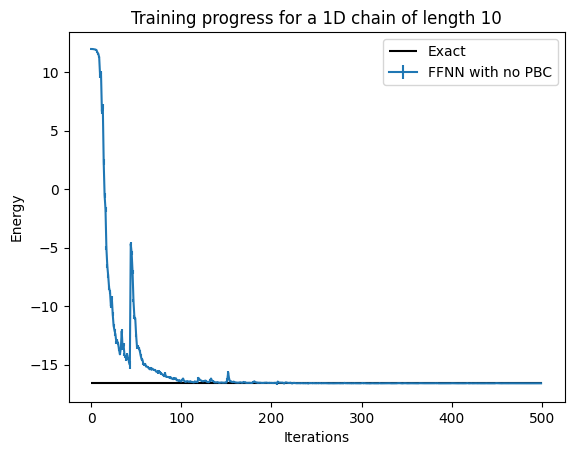

In [ ]:
D = 1
#Test different parameters for training
pbc = False
fix_magnetization = True
optimizer = "SDG"
sampler = "Exchange"

J1 = 1
J2 = 0.2

# Hyperparameters
training_steps =500
n_samples = 1008
learning_rate = 0.02
diag_shift = 0.01
plot_observables = False


ground_states = []
final_energies = []
convergences = []
energies = []
errors = []

for size in range(10,11):
    if size*D > 3:
        n_egval = size
    else:
        n_egval = 1
    print("Running model for chain of length:", size)


    L = size
    g, hi = create_hilbert_space(D, L, pbc, fix_magnetization)
    H = build_heisenberg_hamiltonian(hi, J1, J2, D, L, g, pbc)
    OX, OY, OZ, OTot = define_observables(hi, g)
    observables = {'PauliX': OX, 'PauliY': OY, 'PauliZ': OZ, 'PauliTot': OTot }

    if L**D <= 18:
        Eg, eigvals, eigvecs = exact_diagonalization(H, n_egval)
    else:
        Eg = -1.63*(L**D) + 0.19
    ground_states.append(Eg)

    #Test different models
    model = FFNN()
    #model = SymFFNN()
    #model = NKRBM(alpha = 1)


    gs, vs = define_training_parameters(H, hi, g, model, optimizer, sampler, n_samples, learning_rate, diag_shift)
    log , energy, error = run_model(gs, H, vs, training_steps, observables, Eg)


    data = log.data
    energies.append(energy)
    errors.append(error)
    con_step, e_conv, e_final = convergence_point(data, Eg)
    final_energies.append(e_final)
    convergences.append(con_step)

plot(data, Eg, plot_observables, training_steps)
for e in energies:
    print(e)

/usr/local/lib/python3.11/dist-packages/numpy/ma/core.py:3397: ComplexWarning: Casting complex values to real discards the imaginary part
  _data[indx] = dval


(-16.637564232451545-0.07958182410797515j)
-16.6045+0.0003j ± 0.0021 [σ²=0.0042, R̂=1.0053]


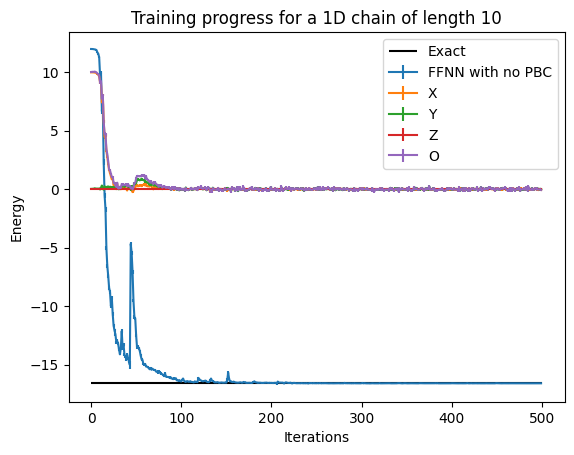

In [ ]:
# Plot again to view observables
plot_observables = True
plot(data, Eg, plot_observables, training_steps)
for e in energies:
    print(e)